In [2]:
%pip install -q rocketpy
from rocketpy import Environment, SolidMotor,GenericMotor, Rocket, Flight, Fluid, MassBasedTank, CylindricalTank, LiquidMotor
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
def build_rocket(m = 17, thrust = None, incl = 84, windy = 3, small = 0.5, large = 6.7692137, large_trigger = 400, fins_span = 0.08, fins_pos = 0.35, nose_length = 0.46):
  env = Environment(elevation = 0)
  env.set_atmospheric_model(
      type = "custom_atmosphere",
      wind_u = windy,
  )


  ethanol = Fluid(
      name="ethanol",
      density=789
  )

  lox = Fluid(
      name="lox",
      density=1140
  )

  gas = Fluid(
      name="gas",
      density=0
  )

  tank_geometry = CylindricalTank(
      radius_function=0.06,
      height=0.6,
  )

  def fuel_mass(t):
      return max(0, 0.45 * (10 - t))

  ethanol_tank = MassBasedTank(
      name = "ethanol tank",
      geometry = tank_geometry,
      flux_time = 10,
      liquid = ethanol,
      gas = gas,
      liquid_mass = fuel_mass,
      gas_mass = 0
  )

  def oxidizer_mass(t):
      return max(0, 0.56 * (10 - t))


  lox_tank = MassBasedTank(
      name = "lox tank",
      geometry = tank_geometry,
      flux_time = 10,
      liquid = lox,
      gas = gas,
      liquid_mass = oxidizer_mass,
      gas_mass = 0,
  )
  if thrust == None:
    thrust_file = pd.read_csv("https://raw.githubusercontent.com/RocketPy-Team/RocketPy/develop/data/rockets/hedy/hedy_thrust_euroc_launch.csv").to_numpy()
  else:
    thrust_file = thrust

  motor = LiquidMotor(
      thrust_source = thrust_file,
      dry_mass = 0,
      burn_time = 10,
      dry_inertia = (0, 0, 0),
      nozzle_radius = 0.0375,
      nozzle_position = 0,
      center_of_dry_mass_position = 0
  )

  motor.add_tank(ethanol_tank, position=0.9)
  motor.add_tank(lox_tank, position=2)


  r = 0.065
  inertia3 = 0.5 * m * r**2
  inertia12 = 1.0 / 12.0 * m * (3 * r**2 + 3.5**2)
  rocket = Rocket(
      radius = 0.065,
      mass = m,
      inertia = (inertia12, inertia12, inertia3),
      power_off_drag = 0.5,
      power_on_drag = 0.5,
      center_of_mass_without_motor = 1.8
  )
  rocket.add_motor(motor = motor, position = 0)

  rocket.add_nose(
      length = nose_length,
      kind = "conical",
      position = 3.7
  )

  rocket.add_trapezoidal_fins(
      n = 4,
      root_chord = 0.25,
      tip_chord = 0.06,
      span = fins_span,
      position = fins_pos
  )


  rocket.add_parachute(
      name = "small parachute",
      cd_s = small,
      trigger = "apogee",
      lag = 1
  )

  rocket.add_parachute(
      name = "large parachute",
      cd_s = large,
      trigger = large_trigger,
      lag = 4
  )

  flight = Flight(
      rocket = rocket,
      environment = env,
      rail_length=12,
      inclination = incl
  )
  return flight, motor

In [4]:
def plot(x_data, y_data, x_name, y_name):
  plt.xlabel(x_name)
  plt.ylabel(y_name)
  plt.grid(True)
  plt.plot(x_data, y_data)
  plt.show()

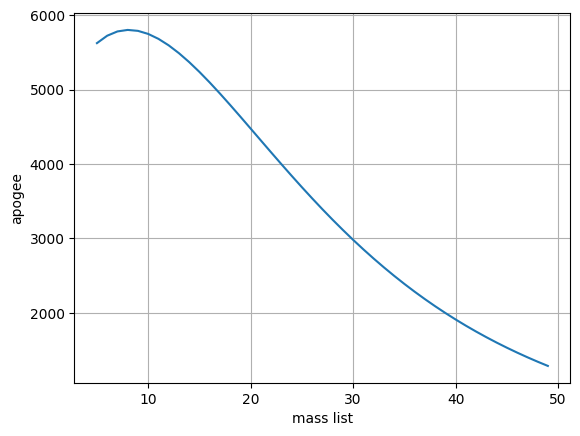

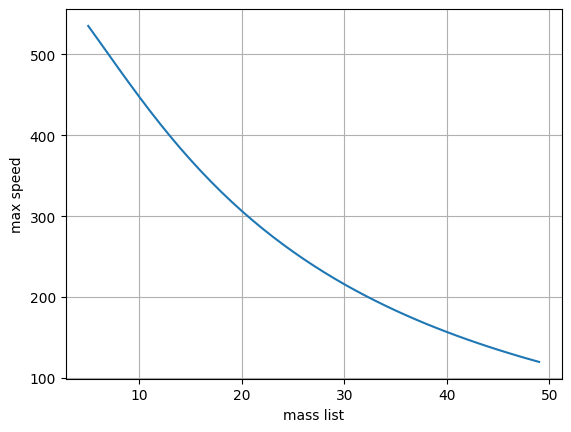

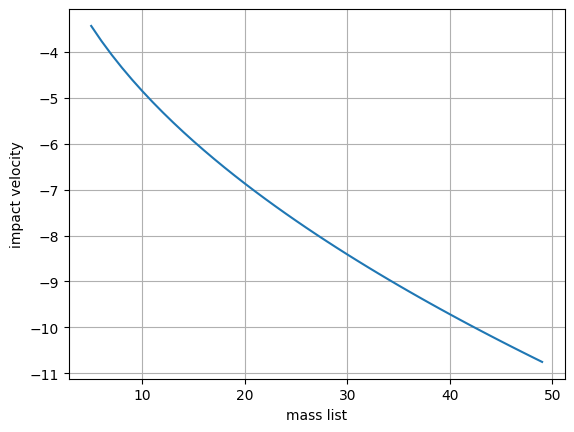

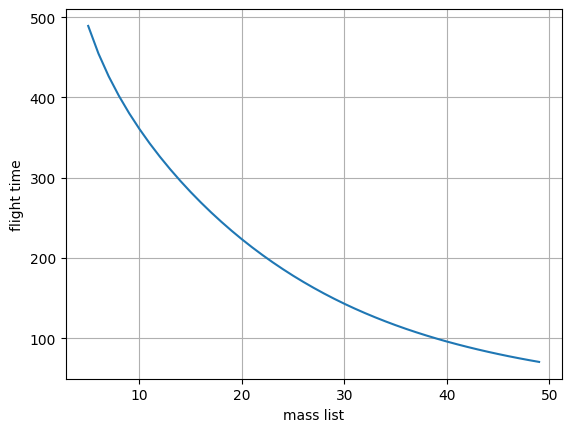

In [5]:
#mass changes
mass_list = []

apogees = []
max_speed = []
impact_velocity = []
flight_time = []

for mass_i in range(5,50):
  flight, motor = build_rocket(m = mass_i)
  mass_list.append(mass_i)

  apogees.append(flight.apogee)
  max_speed.append(flight.max_speed)
  impact_velocity.append(flight.impact_velocity)
  flight_time.append(flight.t_final)

plot(mass_list, apogees, "mass list", "apogee")
plot(mass_list, max_speed, "mass list", "max speed")
plot(mass_list, impact_velocity, "mass list", "impact velocity")
plot(mass_list, flight_time, "mass list", "flight time")

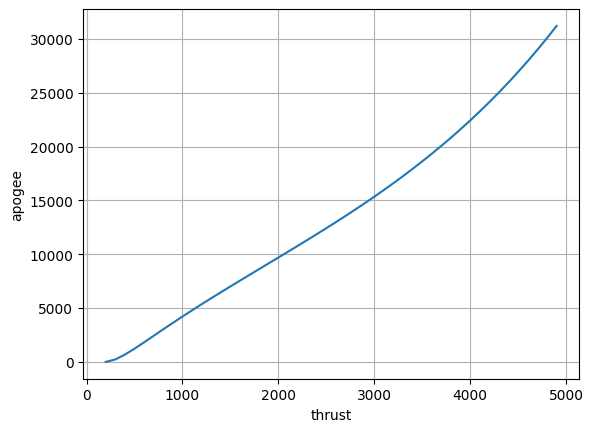

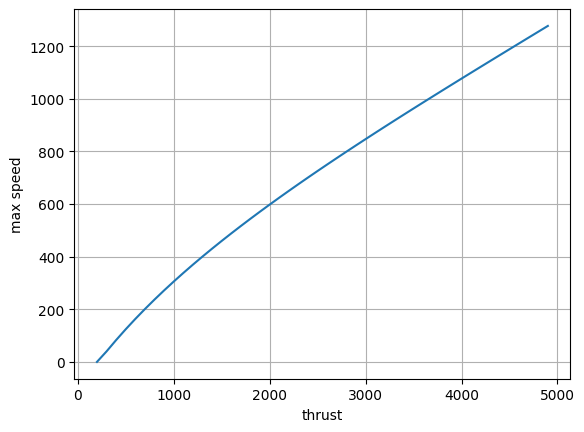

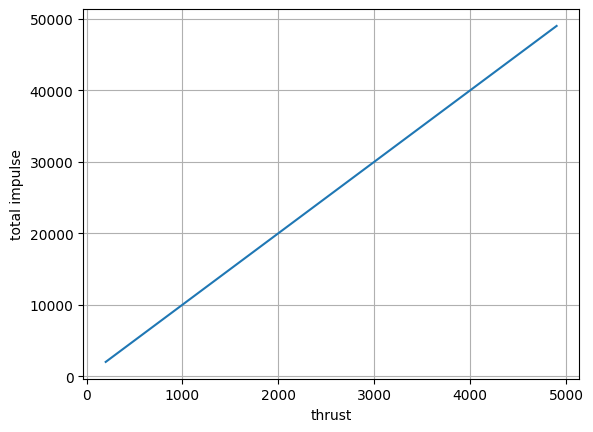

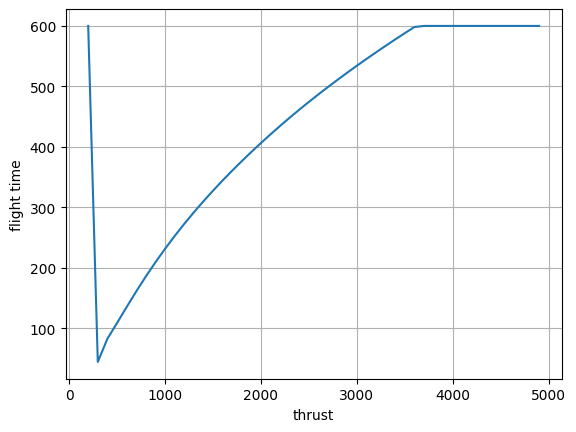

In [6]:
#thrust changes
thrusts_list = []

apogees = []
max_speed = []
total_impulse = []
flight_time = []

for thrust_i in range(200,5000,100):
  flight, motor = build_rocket(thrust=thrust_i)
  thrusts_list.append(thrust_i)

  apogees.append(flight.apogee)
  max_speed.append(flight.max_speed)
  total_impulse.append(motor.total_impulse)
  flight_time.append(flight.t_final)

plot(thrusts_list, apogees, "thrust", "apogee")
plot(thrusts_list, max_speed, "thrust", "max speed")
plot(thrusts_list, total_impulse, "thrust", "total impulse")
plot(thrusts_list, flight_time, "thrust", "flight time")

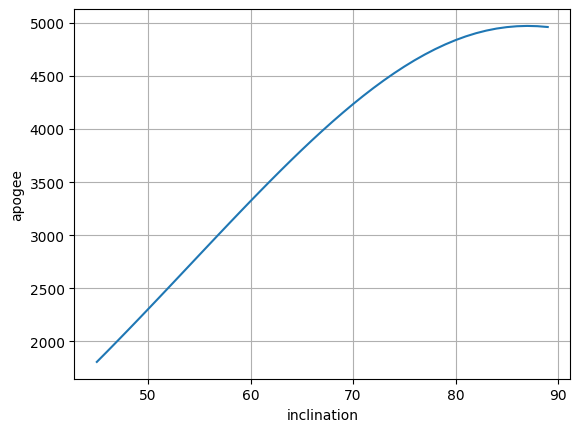

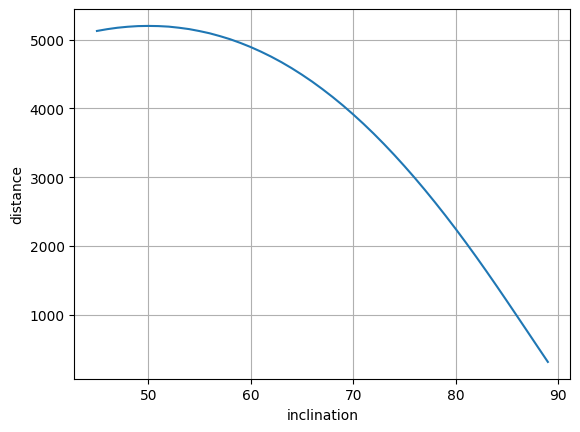

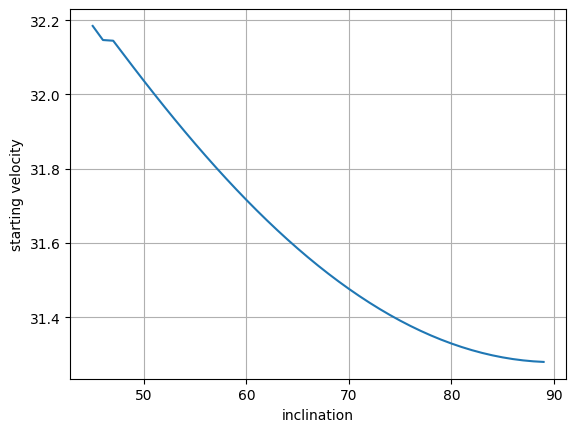

In [7]:
#inclination changes
inclinations = []

apogees = []
distances = []
starting_velocity = []

for inclination_i in range(45, 90):
  flight,motor = build_rocket(incl = inclination_i)
  inclinations.append(inclination_i)

  apogees.append(flight.apogee)
  distances.append(flight.x_impact)
  starting_velocity.append(flight.out_of_rail_velocity)

plot(inclinations, apogees, "inclination", "apogee")
plot(inclinations, distances, "inclination", "distance")
plot(inclinations, starting_velocity, "inclination", "starting velocity")


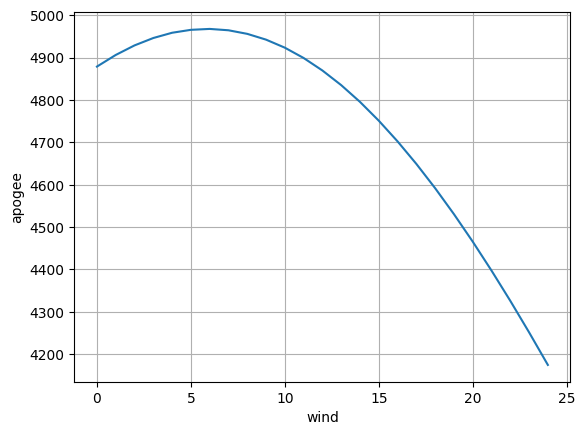

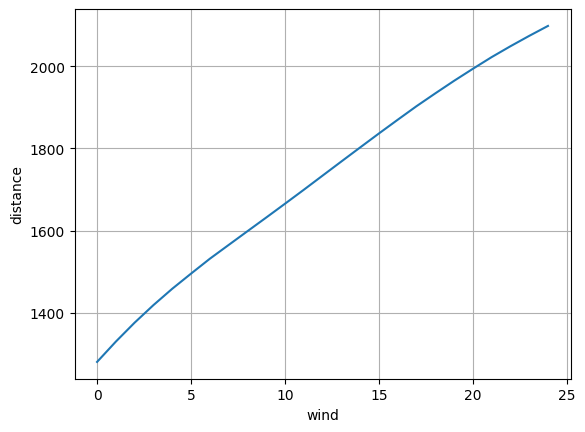

In [8]:
#wind changes
wind = []

apogees = []
distances = []

for wind_i in range(0, 25):
  flight, motor = build_rocket(windy = wind_i)
  wind.append(wind_i)
  apogees.append(flight.apogee)
  distances.append(flight.x_impact)
plot(wind, apogees, "wind", "apogee")
plot(wind, distances, "wind", "distance")



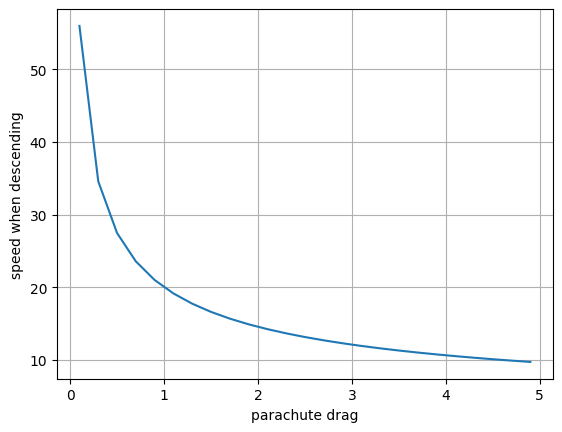

minimal drag: 0.3
maximal drag: 0.9


In [9]:
#small parachute changes
small_i = 0.1
small_drag = []
speedmid = []
while small_i < 5:
  flight, motor = build_rocket(small = small_i)
  small_drag.append(small_i)
  time = (flight.apogee_time) * 3
  speedmid.append(flight.speed(time))
  small_i += 0.2
plot(small_drag, speedmid, "parachute drag", "speed when descending")

min_val = 23
max_val = 46
min_drag = 0
max_drag = 0
for i in range(len(small_drag)):
  if speedmid[i] < max_val and min_drag == 0:
    min_drag = small_drag[i]
  if speedmid[i] < min_val and max_drag == 0:
    max_drag = small_drag[i]

print("minimal drag:", round(min_drag,1))
print("maximal drag:", round(max_drag,1))


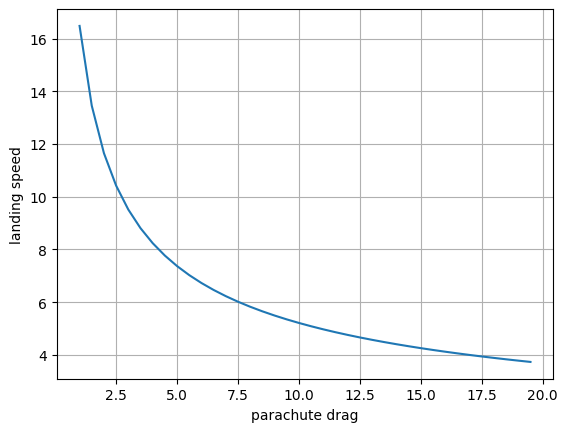

min drag: 3.5


In [10]:
#large parachute changes
large_i = 1
large_drag = []
speed_landing = []
while large_i < 20:
  flight, motor = build_rocket(large = large_i)
  large_drag.append(large_i)
  speed_landing.append(abs(flight.impact_velocity))
  large_i += 0.5

plot(large_drag, speed_landing, "parachute drag", "landing speed")

min_drag = 0
max_speed = 9
for i in range(len(large_drag)):
  if min_drag==0 and speed_landing[i] < max_speed:
    min_drag = large_drag[i]
print("min drag:", min_drag)

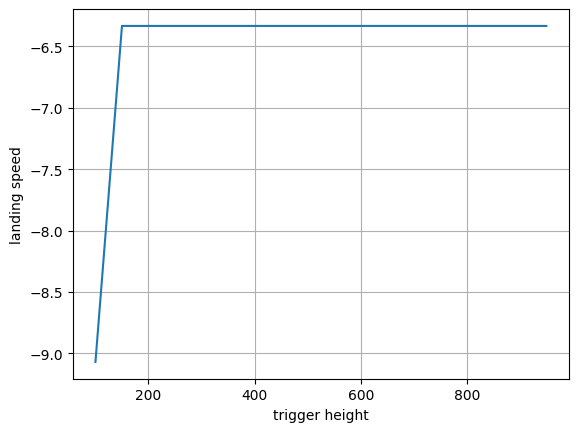

In [11]:
#large parachute trigger
triggers = []
landing_speed = []
for trigger_i in range(100, 1000, 50):
  flight, motor = build_rocket(large_trigger=trigger_i)
  triggers.append(trigger_i)
  landing_speed.append(flight.impact_velocity)
plot(triggers, landing_speed, "trigger height", "landing speed")


/usr/local/lib/python3.13/dist-packages/rocketpy/simulation/flight.py:610: UnstableRocketWarning: The rocket has a negative static margin (-0.22 cal) at motor ignition (t=0), indicating an aerodynamically unstable configuration. Check the placement of fins and nose cone relative to the center of mass.
  self.rocket.warn_if_unstable()


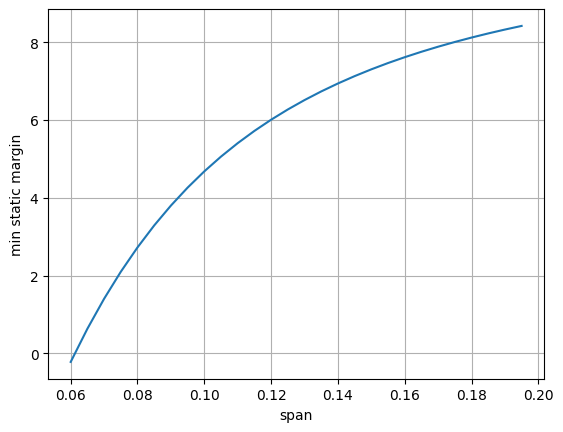

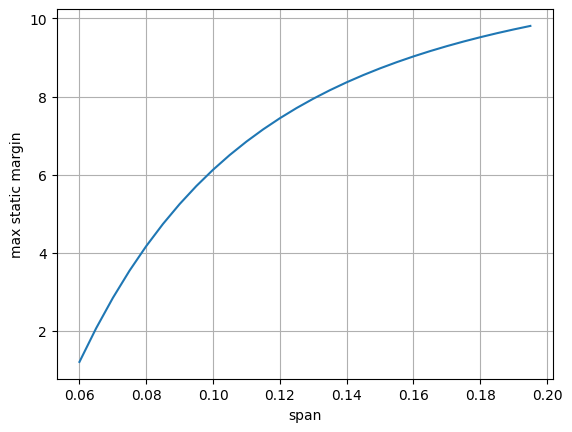

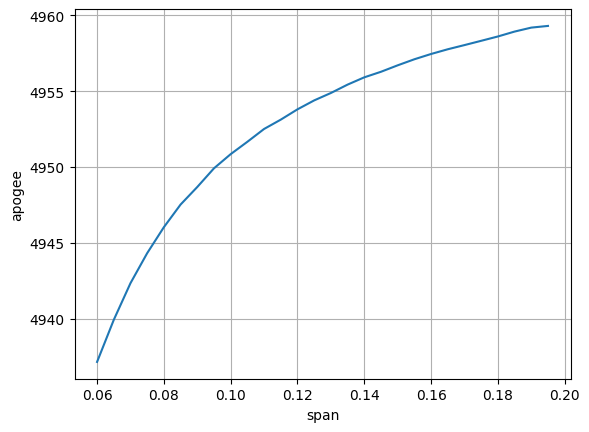

minimal span: 0.075
maximal span: 0.09


In [12]:
#fins span
span = []
min_stability = []
max_stability = []
apogee = []

span_i = 0.06
while span_i < 0.2:
  flight, motor = build_rocket(fins_span = span_i)
  span.append(span_i)
  apogee.append(flight.apogee)
  min_stability.append(flight.min_stability_margin)
  max_stability.append(flight.max_stability_margin)
  span_i += 0.005
  span_i = round(span_i, 3)
plot(span, min_stability, "span", "min static margin")
plot(span, max_stability, "span", "max static margin")
plot(span, apogee, "span", "apogee")

min_span = 0
max_span = 0
min_requirement = 1.5
max_requirement = 5
for i in range(len(min_stability)):
  if min_stability[i] > min_requirement and min_span == 0:
    min_span = span[i]
  if max_stability[i] > max_requirement and max_span == 0:
    max_span = span[i]
print("minimal span:", min_span)
print("maximal span:", max_span)

/usr/local/lib/python3.13/dist-packages/rocketpy/simulation/flight.py:610: UnstableRocketWarning: The rocket has a negative static margin (-0.06 cal) at motor ignition (t=0), indicating an aerodynamically unstable configuration. Check the placement of fins and nose cone relative to the center of mass.
  self.rocket.warn_if_unstable()
/usr/local/lib/python3.13/dist-packages/rocketpy/simulation/flight.py:610: UnstableRocketWarning: The rocket has a negative static margin (-0.31 cal) at motor ignition (t=0), indicating an aerodynamically unstable configuration. Check the placement of fins and nose cone relative to the center of mass.
  self.rocket.warn_if_unstable()


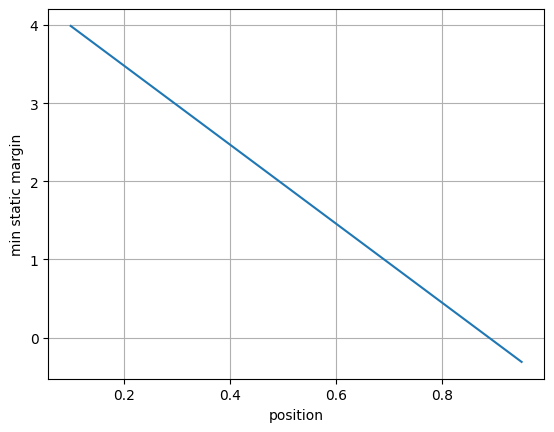

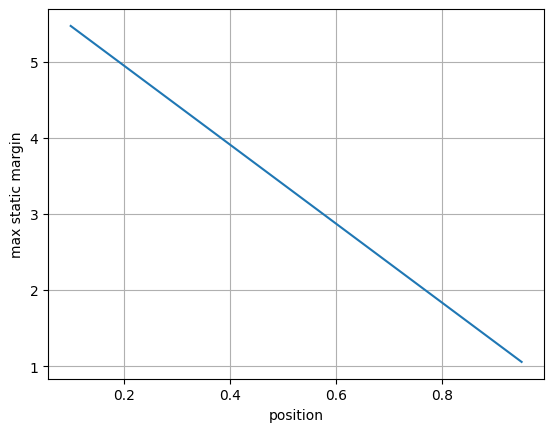

minimal position: 0.2
maximal position: 0.6


In [13]:
#fins position
position = []
min_stability = []
max_stability = []

position_i = 0.1
while position_i < 1:
  flight, motor = build_rocket(fins_pos = position_i)
  position.append(position_i)
  min_stability.append(flight.min_stability_margin)
  max_stability.append(flight.max_stability_margin)
  position_i += 0.05
plot(position, min_stability, "position", "min static margin")
plot(position, max_stability, "position", "max static margin")


min_position = 0
max_position = 0
min_requirement = 1.5
max_requirement = 5
for i in range(len(min_stability)):
  if max_stability[i] < max_requirement and min_position == 0:
    min_position = position[i]
  if min_stability[i] < min_requirement and max_position == 0:
    max_position = position[i]
print("minimal position:", min_position)
print("maximal position:", max_position)

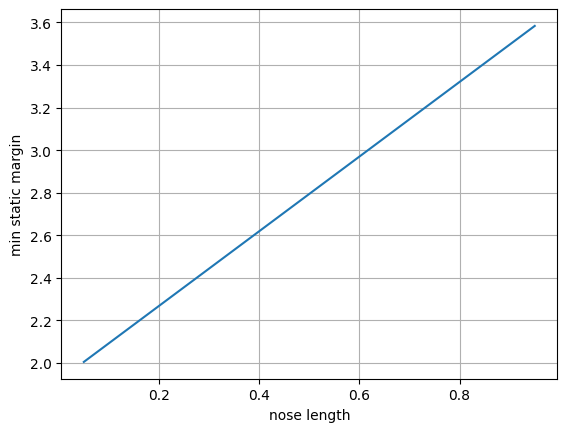

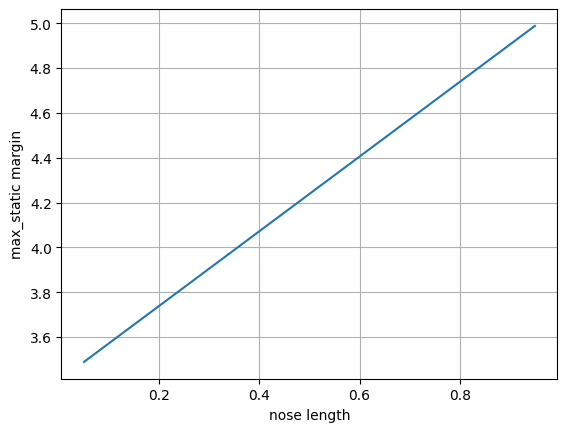

In [14]:
#nose length
length = 0.05
lengths = []
min_static_margin = []
max_static_margin = []
while length < 1:
  flight, motor = build_rocket(nose_length = length)
  lengths.append(length)
  min_static_margin.append(flight.min_stability_margin)
  max_static_margin.append(flight.max_stability_margin)
  length += 0.05
plot(lengths, min_static_margin, "nose length", "min static margin")
plot(lengths, max_static_margin, "nose length", "max_static margin")
